In [50]:
import numpy as np
import pandas as pd
import csv
import matplotlib.pyplot as plt
from fmqa import FMBQM
import dimod

In [51]:
df = pd.read_csv('compl_enum_cstr_5_baron_hull.csv')

def load_grid(filename="compl_enum_cstr_5_baron_hull.csv"):
    """
    Load grid data from CSV.
    Expected CSV columns: "x", "y", "Objective", among others.
    Returns a dictionary mapping (x, y) tuples to the objective value.
    """
    grid_data = {}
    with open(filename, "r") as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                # Convert x and y values to integers
                x_val = int(row["x"])
                y_val = int(row["y"])
                # Convert objective value to float
                obj_val = float(row["Objective"])
                grid_data[(x_val, y_val)] = obj_val
            except Exception as e:
                # Skip rows with conversion issues
                continue

    # Compute the minimum among finite objective values
    finite_values = [v for v in grid_data.values() if not np.isnan(v)]
    x_min = min(finite_values) if finite_values else None
    x_max = max(finite_values) if finite_values else None     
    return grid_data, x_min, x_max
# Load the data from grid.csv
grid_data, x_min, x_max = load_grid()

# Determine grid bounds from the keys of grid_data
xs = [pt[0] for pt in grid_data.keys()]
ys = [pt[1] for pt in grid_data.keys()]
min_x, max_x = min(xs), max(xs)
min_y, max_y = min(ys), max(ys)
print("Grid bounds:")
print("x in [{}, {}]".format(min_x, max_x))
print("y in [{}, {}]".format(min_y, max_y))

Grid bounds:
x in [1, 5]
y in [1, 5]


In [52]:
# Integer to binary weighted bit encoding
def int_to_bits(n: int, upper: int, lsb_first: bool = True):
    """
    Encode n in binary using the minimum number of bits for [0, upper].
    Returns a list of 0/1 (LSB first by default).
    """
    if not (0 <= n <= upper):
        raise ValueError(f"value {n} outside [0, {upper}]")

    m = int(np.ceil(np.log2(upper + 1)))      # cast to int

    bits = [(n >> k) & 1 for k in range(m)]
    if not lsb_first:
        bits.reverse()
    return bits

int_to_bits(3, 5, lsb_first=True)  # Example usage

def coord_bits(x: int, y: int,
               x_max: int, y_max: int,
               lsb_first: bool = True):
    """
    Given (x, y) and their maxima, return a tuple:
        ([bits for x], [bits for y])
    """
    x_bits = int_to_bits(x, x_max, lsb_first)
    y_bits = int_to_bits(y, y_max, lsb_first)
    all_bits = x_bits + y_bits
    return ''.join(str(bit) for bit in all_bits)

print(coord_bits(5, 1, x_max=5, y_max=5, lsb_first=False))  # Output: '101001' 


101001


In [53]:
# Load the data from grid.csv
grid_data, x_min, x_max = load_grid()

# PENALTY = 1e6  # adjust this penalty as appropriate
PENALTY = np.inf # use infinity as penalty for infeasible points
# PENALTY = np.nan  # use NaN as penalty for infeasible points
# PENALTY = None  # use None as penalty for infeasible points

def obj_funct(x):
    """
    Given a candidate point x (a list or 1-D numpy array with 2 elements),
    this function rounds x to the nearest integers and returns the objective value
    if the point exists in grid_data and is feasible.
    Otherwise, returns a penalty value.
    """
    # Round the candidate coordinates to nearest integers
    x_int = int(round(x[0]))
    y_int = int(round(x[1]))
    
    # Check that x_int and y_int are numbers (optional check)
    if not isinstance(x_int, (int, float)) or not isinstance(y_int, (int, float)):
        return PENALTY
    
    # If the point exists in the grid, check its objective value.
    if (x_int, y_int) in grid_data:
        obj_val = grid_data[(x_int, y_int)]
        # Return penalty if the objective is NaN.
        if np.isnan(obj_val):
            return PENALTY
        else:
            return obj_val
    else:
        # If the point is not in the grid, return the penalty.
        return PENALTY

In [54]:
# Test for the obj_funct function
obj_funct([7,5])

inf

$$
f(x)=-1+\frac{\text{raw val} - x_{min}}{x_{max} - x_{min}}
$$

In [55]:
def scale_point(x, y, grid_data, x_min, x_max):
    """
    Compute the arctan-based scaled transformation for a point (x, y).
    Maps x_min -> -1 and infinity -> 1.
    
    Parameters:
      - x, y: coordinates (floats)
      - grid_data: dict from load_grid
      - x_min: minimum objective value from load_grid
      - alpha: scale parameter (default=1)
    
    Returns:
      - scaled value in [-1, 1]
    """
    raw_val = obj_funct([x, y])

    if raw_val == np.inf:
        return 1.0
    else:
      delta = raw_val - x_min
      diff = x_max - x_min
      scaled = -1 + delta / diff
      return float(scaled)

# scale_point(1, 1, grid_data, x_min, x_max)

for i in range(1,6):
    for j in range(1,6):
        x = i
        y = j
        print(f"({x}, {y}) -> {scale_point(x, y, grid_data, x_min, x_max)}")

(1, 1) -> 0.0
(1, 2) -> 1.0
(1, 3) -> 1.0
(1, 4) -> 1.0
(1, 5) -> 1.0
(2, 1) -> -0.8534528868666731
(2, 2) -> -0.8534528868255523
(2, 3) -> 1.0
(2, 4) -> 1.0
(2, 5) -> 1.0
(3, 1) -> -0.9629434477163442
(3, 2) -> -0.9629434477178695
(3, 3) -> -0.9629434477163381
(3, 4) -> 1.0
(3, 5) -> 1.0
(4, 1) -> -0.9893999436017751
(4, 2) -> -0.9893999440820028
(4, 3) -> -0.9893999436020154
(4, 4) -> -0.989481015202418
(4, 5) -> 1.0
(5, 1) -> -0.9900065685663152
(5, 2) -> -0.9900065685662779
(5, 3) -> -0.9900065688721418
(5, 4) -> -0.990006568599042
(5, 5) -> -1.0


In [56]:
def decode_and_scale(bitstring: str, x_max: int, y_max: int, grid_data, x_min, x_max_obj):
    """
    Given a binary bitstring representing x and y, decode to integers,
    and return the scaled objective value.

    Parameters:
    - bitstring: str (e.g., '101001')
    - x_max, y_max: upper bounds for x and y to determine bit lengths
    - grid_data: dictionary from load_grid()
    - x_min, x_max_obj: objective value bounds for scaling

    Returns:
    - scaled value from scale_point
    """
    # Determine number of bits for x and y
    x_bits_len = int(np.ceil(np.log2(x_max + 1)))
    y_bits_len = int(np.ceil(np.log2(y_max + 1)))

    if len(bitstring) != x_bits_len + y_bits_len:
        raise ValueError("Bitstring length mismatch with provided x_max and y_max")

    # Extract bit slices and convert to integers
    x_bits = bitstring[:x_bits_len]
    y_bits = bitstring[x_bits_len:]

    x_int = int(x_bits, 2)
    y_int = int(y_bits, 2)

    return scale_point(x_int, y_int, grid_data, x_min, x_max_obj)

bitstring = '101001'  # This corresponds to (5, 1) if x=5, y=1 and both max=5
result = decode_and_scale(bitstring, x_max=5, y_max=5, grid_data=grid_data, x_min=x_min, x_max_obj=x_max)
print(f"{bitstring} → scaled value: {result}")

101001 → scaled value: -0.9900065685663152


Initial random seed size: 6
Total samples after SA loop: 6

→ Best sample #0:
   Bitstring = 101001
   Coord     = (5, 1)
   Scaled val= -0.9900


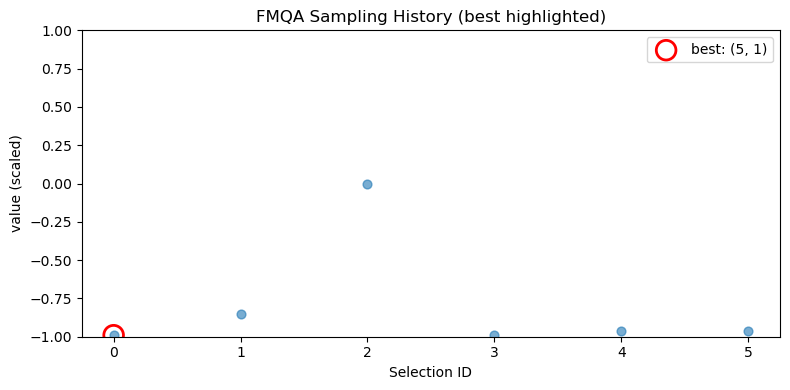


Trajectory of sampled (bitstring → coord → scaled objective) up to sample #15:
  sample  1 → 101001 → (5, 1) → scaled obj = -0.9900
  sample  2 → 010001 → (2, 1) → scaled obj = -0.8535
  sample  3 → 001001 → (1, 1) → scaled obj = 0.0000
  sample  4 → 101010 → (5, 2) → scaled obj = -0.9900
  sample  5 → 011010 → (3, 2) → scaled obj = -0.9629
  sample  6 → 011001 → (3, 1) → scaled obj = -0.9629

Sampled points after initial 6 training points (i.e., SA-added only):


In [57]:
import random
random.seed(42)          # reproducible seeding
n_seed = 6              # <-- how many points to start with

# FMQA surrogate and sampling history

# Step 1: Build a random seed set
x_max_idx, y_max_idx = max_x, max_y
all_keys = list(grid_data.keys())
seed_coords = random.sample(all_keys, n_seed)

X = np.array([
    [int(b) for b in coord_bits(x, y, x_max_idx, y_max_idx, lsb_first=False)]
    for x, y in seed_coords
], dtype=int)

y = np.array([
    scale_point(x, y, grid_data, x_min, x_max)
    for x, y in seed_coords
], dtype=float)

# Train FMQA model
model = FMBQM.from_data(X, y)
sampler = dimod.SimulatedAnnealingSampler()

# Keep histories (start with the seed only)
history_coords = seed_coords.copy()
history_y = y.tolist()
history_bits = [
    ''.join(str(bit) for bit in row)
    for row in X
]

# Bit lengths
nbit_x = int(np.ceil(np.log2(x_max_idx + 1)))
nbit_y = int(np.ceil(np.log2(y_max_idx + 1)))
total_bits = nbit_x + nbit_y

# Sampling loop (FMQA-style acquisition)
for _ in range(5):
    res = sampler.sample(model, num_reads=10)
    bits_arr = res.record['sample']
    
    new_y = []
    new_coords = []
    new_bitstrings = []
    valid_bits = []

    for bits in bits_arr:
        bx = bits[:nbit_x]
        by = bits[nbit_x:nbit_x + nbit_y]
        bitstring = ''.join(str(b) for b in bits)

        xi = int(''.join(str(b) for b in bx), 2)
        yi = int(''.join(str(b) for b in by), 2)
        coord = (xi, yi)

        # Only accept feasible and *new* coordinates
        if coord in grid_data and not np.isnan(grid_data[coord]) and coord not in history_coords:
            valid_bits.append(bits)
            new_coords.append(coord)
            new_y.append(scale_point(xi, yi, grid_data, x_min, x_max))
            new_bitstrings.append(bitstring)

    # Extend histories with valid entries
    if new_coords:
        history_coords.extend(new_coords)
        history_y.extend(new_y)
        history_bits.extend(new_bitstrings)

        # Retrain on augmented dataset
        X = np.vstack([X, valid_bits])
        y = np.hstack([y, new_y])
        model.train(X, y)

# Find the best result so far
best_idx = int(np.argmin(history_y))
best_coord = history_coords[best_idx]
best_val = history_y[best_idx]
best_bitstring = history_bits[best_idx]

print(f"Initial random seed size: {n_seed}")
print(f"Total samples after SA loop: {len(history_coords)}")

print(f"\n→ Best sample #{best_idx}:")
print(f"   Bitstring = {best_bitstring}")
print(f"   Coord     = {best_coord}")
print(f"   Scaled val= {best_val:.4f}")

# Plot history
plt.figure(figsize=(8, 4))
plt.scatter(range(len(history_y)), history_y, s=40, alpha=0.6)
plt.scatter([best_idx], [best_val], s=200,
            facecolors='none', edgecolors='red', linewidths=2,
            label=f"best: {best_coord}")
plt.xlabel("Selection ID")
plt.ylabel("value (scaled)")
plt.ylim([-1, 1])
plt.legend()
plt.title("FMQA Sampling History (best highlighted)")
plt.tight_layout()
plt.show()

# Show trajectory of first 15 samples
print("\nTrajectory of sampled (bitstring → coord → scaled objective) up to sample #15:")
for i in range(min(15, len(history_coords))):
    print(f"  sample {i+1:2d} → {history_bits[i]} → {history_coords[i]} → scaled obj = {history_y[i]:.4f}")

n_init = n_seed  # initial training points count
print(f"\nSampled points after initial {n_init} training points (i.e., SA-added only):")
for idx in range(n_init, len(history_coords)):
    print(f"sample {idx+1:2d} → {history_bits[idx]} → {history_coords[idx]}")

In [58]:
# # FMQA surrogate and sampling history

# # Step 1: Build bit‐encoded design matrix and scaled objectives
# x_max_idx, y_max_idx = max_x, max_y
# keys = list(grid_data.keys())

# X = np.array([
#     [int(b) for b in coord_bits(x, y, x_max_idx, y_max_idx, lsb_first=False)]
#     for x, y in keys
# ], dtype=int)

# y = np.array([
#     scale_point(x, y, grid_data, x_min, x_max)
#     for x, y in keys
# ], dtype=float)

# # Train FMQA model
# model = FMBQM.from_data(X, y)
# sampler = dimod.SimulatedAnnealingSampler()

# # Keep histories
# history_coords = keys.copy()
# history_y = y.tolist()
# history_bits = [  # initial binary encodings
#     ''.join(str(bit) for bit in row)
#     for row in X
# ]

# # Bit lengths
# nbit_x = int(np.ceil(np.log2(x_max_idx + 1)))
# nbit_y = int(np.ceil(np.log2(y_max_idx + 1)))
# total_bits = nbit_x + nbit_y

# # Sampling loop
# for _ in range(5):
#     res = sampler.sample(model, num_reads=10)
#     bits_arr = res.record['sample']
    
#     new_y = []
#     new_coords = []
#     new_bitstrings = []
#     valid_bits = []

#     for bits in bits_arr:
#         bx = bits[:nbit_x]
#         by = bits[nbit_x:nbit_x + nbit_y]
#         bitstring = ''.join(str(b) for b in bits)

#         xi = int(''.join(str(b) for b in bx), 2)
#         yi = int(''.join(str(b) for b in by), 2)
#         coord = (xi, yi)

#         if coord in grid_data and not np.isnan(grid_data[coord]):
#             # Save only valid samples
#             valid_bits.append(bits)
#             new_coords.append(coord)
#             new_y.append(scale_point(xi, yi, grid_data, x_min, x_max))
#             new_bitstrings.append(bitstring)
#         else:
#             print(f"Skipping invalid sample {bitstring} → {coord}")

#     # Extend histories with valid entries
#     history_coords.extend(new_coords)
#     history_y.extend(new_y)
#     history_bits.extend(new_bitstrings)

#     # Retrain on valid bit rows
#     if valid_bits:
#         X = np.vstack([X, valid_bits])
#         y = np.hstack([y, new_y])
#         model.train(X, y)

# # Find the best result
# best_idx = int(np.argmin(history_y))
# best_coord = history_coords[best_idx]
# best_val = history_y[best_idx]
# best_bitstring = history_bits[best_idx]

# print(f"\n→ Best sample #{best_idx}:")
# print(f"   Bitstring = {best_bitstring}")
# # print(f"   Coord     = {best_coord}")
# print(f"   Scaled val= {best_val:.4f}")

# # Plot history
# plt.figure(figsize=(8, 4))
# plt.scatter(range(len(history_y)), history_y, s=40, alpha=0.6)
# plt.scatter([best_idx], [best_val], s=200,
#             facecolors='none', edgecolors='red', linewidths=2,
#             label=f"best: {best_coord}")
# plt.xlabel("Selection ID")
# plt.ylabel("value (scaled)")
# plt.ylim([-1, 1])
# plt.legend()
# plt.title("FMQA Sampling History (best highlighted)")
# plt.tight_layout()
# plt.show()

# # Show trajectory of sampled coords and bitstrings
# print("\nTrajectory of sampled (bitstring → coord → scaled objective) up to sample #15:")
# for i in range(min(15, len(history_coords))):
#     print(f"  sample {i+1:2d} → {history_bits[i]} → {history_coords[i]} → scaled obj = {history_y[i]:.4f}")

# n_init = len(keys)
# print(f"\nSampled points after initial {n_init} training points:")
# for idx in range(n_init, len(history_coords)):
#     print(f"sample {idx+1:2d} → {history_bits[idx]} → {history_coords[idx]}")


In [59]:
# === NEW CELL: Recover surrogate objective and compare to ground truth ===

import numpy as np
import pandas as pd

# --- Helpers ---

def bitstring_to_xy(bitstring: str, nbit_x: int, nbit_y: int):
    """Decode bitstring -> (x, y) using the same bit layout as training (x then y, MSB-first)."""
    bx = bitstring[:nbit_x]
    by = bitstring[nbit_x:nbit_x+nbit_y]
    return int(bx, 2), int(by, 2)

def scaled_to_raw(scaled_val: float, x_min: float, x_max: float):
    """Invert your min–max scaling that mapped [x_min, x_max] -> [-1, 1]."""
    return float(x_min + (scaled_val + 1.0) * (x_max - x_min))

def raw_to_scaled(raw_val: float, x_min: float, x_max: float):
    """(For completeness) Forward scaling to [-1, 1]."""
    return float(-1.0 + (raw_val - x_min) / (x_max - x_min))

# Use the variable order stored in the trained BQM to ensure consistent mapping index->label
_var_order = list(model.variables)

def bits_from_bitstring(bitstring: str):
    return [int(c) for c in bitstring]

def sample_dict_from_bitstring(bitstring: str):
    """Map bitstring -> {variable_label: 0/1} following model's internal variable order."""
    bits = bits_from_bitstring(bitstring)
    if len(bits) != len(_var_order):
        raise ValueError(f"Bitstring length {len(bits)} != number of BQM variables {len(_var_order)}")
    return { _var_order[i]: bits[i] for i in range(len(bits)) }

def bqm_predict_scaled(model, bitstring: str):
    """Predicted (scaled) objective from the surrogate BQM via energy()."""
    return float(model.energy(sample_dict_from_bitstring(bitstring)))

def bqm_predict_scaled_manual(model, bitstring: str):
    """Same as above but computed explicitly from offset/linear/quadratic (sanity check)."""
    s = sample_dict_from_bitstring(bitstring)
    val = model.offset
    # linear
    for v, h in model.linear.items():
        val += h * s[v]
    # quadratic
    for (u, v), J in model.quadratic.items():
        val += J * s[u] * s[v]
    return float(val)

def pretty_print_surrogate(model, max_pairs: int = 10):
    """Print surrogate polynomial summary (offset, linear, and top-|J| quadratic terms)."""
    print("\n=== Surrogate (BQM) coefficients ===")
    print("offset:", model.offset)
    lin = dict(model.linear)
    print("\nlinear biases (h_i):")
    for i in sorted(lin):
        print(f"  {i}: {lin[i]}")
    print("\nTop quadratic couplings |J_ij|:")
    quads = list(model.quadratic.items())
    quads_sorted = sorted(quads, key=lambda kv: -abs(kv[1]))
    for k, (vars_ij, Jij) in enumerate(quads_sorted[:max_pairs], start=1):
        print(f"  {k:2d}) {vars_ij}: {Jij}")
    print("...")

# --- Evaluate surrogate on your history and compare with ground truth ---

pred_scaled = []
pred_raw    = []
true_raw    = []
true_scaled = []

rows = []
for b in history_bits:
    # predicted by surrogate
    yhat_s = bqm_predict_scaled(model, b)
    yhat_r = scaled_to_raw(yhat_s, x_min, x_max)

    # decode to (x,y) and fetch true grid value (if present)
    xi, yi = bitstring_to_xy(b, nbit_x, nbit_y)
    gtrue  = grid_data.get((xi, yi), np.inf)

    # the list `history_y` holds the scaled true values for the same order
    # (initial data + valid sampled points). Align by index:
    idx = len(pred_scaled)
    ytrue_s = history_y[idx]

    pred_scaled.append(yhat_s)
    pred_raw.append(yhat_r)
    true_raw.append(gtrue)
    true_scaled.append(ytrue_s)

    rows.append({
        "bitstring": b,
        "x": xi, "y": yi,
        "pred_scaled": yhat_s,
        "true_scaled": ytrue_s,
        "pred_raw": yhat_r,
        "true_raw": gtrue
    })

df_eval = pd.DataFrame(rows)

# Metrics (ignore inf rows if any)
mask_finite = np.isfinite(df_eval["true_raw"])
mse_scaled = float(np.mean((df_eval.loc[mask_finite, "pred_scaled"] - df_eval.loc[mask_finite, "true_scaled"])**2))
mae_raw    = float(np.mean(np.abs(df_eval.loc[mask_finite, "pred_raw"] - df_eval.loc[mask_finite, "true_raw"])))

print("=== Evaluation of trained surrogate on seen samples ===")
print(f"MSE (scaled): {mse_scaled:.6g}")
print(f"MAE (raw)   : {mae_raw:.6g}\n")

# Show first 12 rows for a quick glance
with pd.option_context('display.max_rows', 12, 'display.max_columns', None, 'display.width', 160):
    print(df_eval.head(12).to_string(index=False))

# Check consistency between energy() and manual reconstruction on your best sample
print("\nSanity check on best bitstring:")
print(" best bitstring:", best_bitstring)
print(" energy():", bqm_predict_scaled(model, best_bitstring))
print(" manual  :", bqm_predict_scaled_manual(model, best_bitstring))

# Print a compact summary of the learned polynomial (surrogate objective)
pretty_print_surrogate(model, max_pairs=10)

# --- Convenience: query the surrogate or ground truth for any (x,y) ---

def xy_to_bitstring(x: int, y: int, nbit_x: int, nbit_y: int):
    # Reuse your coord_bits (MSB-first) to ensure the same encoding:
    # coord_bits(x,y, ..., lsb_first=False) returns a string with x-bits then y-bits.
    return coord_bits(x, y, x_max_idx, y_max_idx, lsb_first=False)

def surrogate_objective_raw(model, x: int, y: int):
    """Predicted raw objective from surrogate (via x,y)."""
    b = xy_to_bitstring(x, y, nbit_x, nbit_y)
    return scaled_to_raw(bqm_predict_scaled(model, b), x_min, x_max)

def true_objective_raw(x: int, y: int):
    """Ground-truth raw objective from your CSV/grid."""
    return grid_data.get((x, y), np.inf)

# Example lookups:
example_xy = [(1,1), (5,1), (5,5)]
for (xx, yy) in example_xy:
    print(f"\n(x,y)=({xx},{yy})")
    print("  surrogate raw:", surrogate_objective_raw(model, xx, yy))
    print("  ground truth :", true_objective_raw(xx, yy))


=== Evaluation of trained surrogate on seen samples ===
MSE (scaled): 0.706207
MAE (raw)   : 5.22668

bitstring  x  y  pred_scaled  true_scaled  pred_raw  true_raw
   101001  5  1    -1.946104    -0.990007 -3.393101  3.130198
   010001  2  1    -1.677674    -0.853453 -1.561646  4.061882
   001001  1  1     0.000000     0.000000  9.884852  9.884852
   101010  5  2    -1.946104    -0.990007 -3.393101  3.130198
   011010  3  2    -1.892905    -0.962943 -3.030130  3.314845
   011001  3  1    -1.892905    -0.962943 -3.030133  3.314845

Sanity check on best bitstring:
 best bitstring: 101001
 energy(): -1.946104347705841
 manual  : -1.946104347705841

=== Surrogate (BQM) coefficients ===
offset: -0.3090660274028778

linear biases (h_i):
  0: -0.4391510486602783
  1: -0.44682639837265015
  2: -0.3008372187614441
  3: 0.0011785489041358232
  4: -0.37326139211654663
  5: -0.26777711510658264

Top quadratic couplings |J_ij|:
   1) (4, 2): 1.0
   2) (2, 0): -0.9109998345375061
   3) (5, 2): 0.877

In [60]:
# === NEW CELL: retrain with symmetric scaling [-1, 1] and re-evaluate ===

def scale_point_sym(x, y, grid_data, x_min, x_max):
    raw = obj_funct([x, y])
    if raw == np.inf:
        return 1.0  # keep invalid at top
    # map [x_min, x_max] -> [-1, 1]
    return float(2.0*(raw - x_min)/(x_max - x_min) - 1.0)

# rebuild training data with symmetric scaling
X_sym = np.array([
    [int(b) for b in coord_bits(x, y, x_max_idx, y_max_idx, lsb_first=False)]
    for (x, y) in keys
], dtype=int)

y_sym = np.array([
    scale_point_sym(x, y, grid_data, x_min, x_max)
    for (x, y) in keys
], dtype=float)

model_sym = FMBQM.from_data(X_sym, y_sym)

# Evaluate on the same history (bitstrings you already collected)
def energy_to_raw_sym(e):
    # invert symmetric scaling [-1,1] -> raw
    return float(x_min + 0.5*(e + 1.0)*(x_max - x_min))

pred_scaled_sym = []
pred_raw_sym = []
true_raw_vals = []
true_scaled_sym = []

for i, b in enumerate(history_bits):
    e = float(model_sym.energy({j:int(b[j]) for j in range(len(b))}))
    pred_scaled_sym.append(e)
    pred_raw_sym.append(energy_to_raw_sym(e))
    xi = int(b[:nbit_x], 2); yi = int(b[nbit_x:nbit_x+nbit_y], 2)
    tr = grid_data.get((xi, yi), np.inf)
    true_raw_vals.append(tr)
    # recompute symmetric scaled truth
    if np.isfinite(tr):
        true_scaled_sym.append(2.0*(tr - x_min)/(x_max - x_min) - 1.0)
    else:
        true_scaled_sym.append(1.0)

mask = np.isfinite(true_raw_vals)
mse_scaled_sym = float(np.mean((np.array(pred_scaled_sym)[mask] - np.array(true_scaled_sym)[mask])**2))
mae_raw_sym = float(np.mean(np.abs(np.array(pred_raw_sym)[mask] - np.array(true_raw_vals)[mask])))

print("With symmetric scaling [-1,1]:")
print(" MSE (scaled):", mse_scaled_sym)
print(" MAE (raw)   :", mae_raw_sym)


With symmetric scaling [-1,1]:
 MSE (scaled): 0.025192971302134864
 MAE (raw)   : 0.5383842449859454


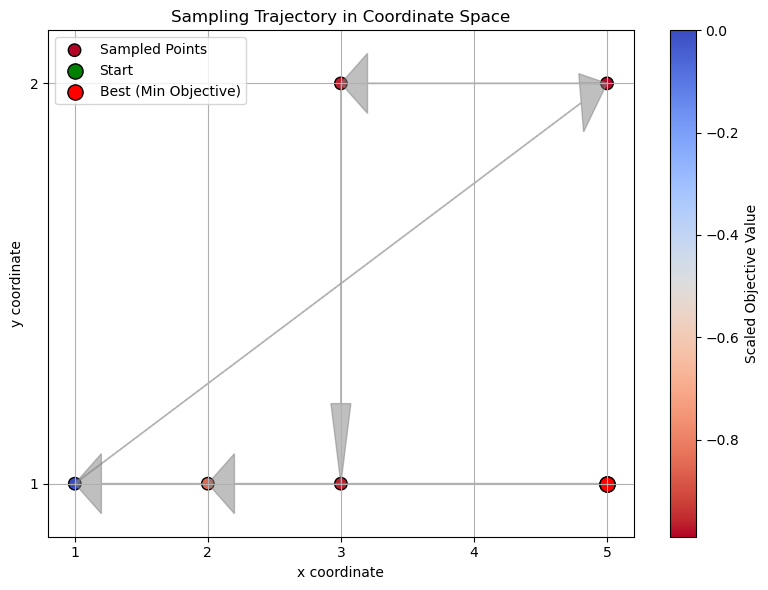

In [61]:
from matplotlib.ticker import MaxNLocator

# Extract X and Y from sampled coordinates
x_coords = [coord[0] for coord in history_coords]
y_coords = [coord[1] for coord in history_coords]
objectives = history_y

# Identify best (minimum objective) sample
best_idx = int(np.argmin(objectives))
best_coord = history_coords[best_idx]

plt.figure(figsize=(8, 6))

# Plot sampled points as scatter
sc = plt.scatter(x_coords, y_coords, c=objectives, cmap='coolwarm_r', s=80, edgecolors='k', label='Sampled Points')

# Draw trajectory arrows
for i in range(1, len(history_coords)):
    x_prev, y_prev = history_coords[i - 1]
    x_curr, y_curr = history_coords[i]
    plt.arrow(x_prev, y_prev, x_curr - x_prev, y_curr - y_prev,
              length_includes_head=True, head_width=0.15, head_length=0.2,
              fc='gray', ec='gray', alpha=0.5)

# Mark first point
plt.scatter(x_coords[0], y_coords[0], color='green', s=120, edgecolors='k', label='Start')

# Mark best (minimum) point
plt.scatter(best_coord[0], best_coord[1], color='red', s=120, edgecolors='k', label='Best (Min Objective)')

# Force integer ticks on both axes
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

# Labels and styling
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.title("Sampling Trajectory in Coordinate Space")
plt.colorbar(sc, label="Scaled Objective Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()